In [2]:
import cupy as cp
import pandas

In [ ]:
data = cp.array(pandas.read_csv('mnist.csv'))

cp.random.shuffle(data)

# first 2000 for testing
test_data = data[:2000]

# next 4000 for early stopping
dev_data = data[2000:6000]

# remaining for training
train = data[6000:]

datapoints = train.shape[0]
pixels = train.shape[1] - 1

labels = train[:, 0]
pics = (train[:, 1:] / 255).T

testDatapoints = test_data.shape[0]
testLabels = test_data[:, 0]
testPics = (test_data[:, 1:] / 255).T

devDatapoints = dev_data.shape[0]
devLabels = dev_data[:, 0]
devPics = (dev_data[:, 1:] / 255).T

In [4]:
one_hot = cp.zeros((datapoints, 10), dtype = int)
one_hot[cp.arange(datapoints), labels] = 1
one_hot = one_hot.T

dev_hot = cp.zeros((devDatapoints, 10), dtype = int)
dev_hot[cp.arange(devDatapoints), devLabels] = 1
dev_hot = dev_hot.T

In [5]:
layers = [pixels, 16, 16, 10] # dont touch first and last entries, change rest to modify hidden layers

weights = list()
biases = list()

for i in range(len(layers)):
    weights.append(cp.random.randn(layers[i], layers[i - 1]) * cp.sqrt(1 / layers[i - 1])) # xavier initialisation by scaling normal distribution
    biases.append(cp.zeros((layers[i], 1)))

In [6]:
def ReLU(arr):
    ret = arr.copy()
    mask = ret < 0
    ret[mask] = 0
    return ret

In [7]:
def ReLU_prime(arr):
    ret = cp.zeros(arr.shape)
    mask = arr > 0
    ret[mask] = 1
    return ret

In [8]:
def softmax(arr):
    ret = arr.copy()
    ret -= cp.max(ret, axis = 0, keepdims = True) # overflow safety
    denom = cp.sum(cp.exp(ret), axis = 0)
    ret = cp.exp(ret) / denom
    return ret

In [9]:
epochs = 10000
learningRate = .1
epsilon = 1e-10 # prevent log(0) domain error
batch_size = 128

# for early stopping

fails = 0
patience = 25
bestLoss = float("inf")
recordWs = list()
recordBs = list()

In [10]:
for i in range(epochs):
    
    perm = cp.random.permutation(datapoints)
    pics = pics[:, perm]
    one_hot = one_hot[:, perm]

    # mini-batching

    for k in range(0, datapoints, batch_size):
        batchPics = pics[:, k:k + batch_size]
        batchHot = one_hot[:, k:k + batch_size]
        currentBatchSize = batchPics.shape[1] # datapoints / batchSize may not be an int

        # forward propagation

        Zs = [batchPics,]
        As = [batchPics,]

        for j in range(1, len(layers)):
            Z = cp.matmul(weights[j], As[j - 1]) + biases[j]
            Zs.append(Z)

            A = ReLU(Z)
            As.append(A)

        As.pop()
        pred = softmax(Zs[-1])
        As.append(pred)

        # backwards propagation

        deltaZ = pred - batchHot

        deltaWs = list()
        deltaBs = list()

        for j in range(len(layers) - 1, 0, -1):
            deltaW = cp.matmul(deltaZ, As[j - 1].T) / currentBatchSize
            deltaWs.append(deltaW)

            deltaB = cp.sum(deltaZ, axis = 1, keepdims = True) / currentBatchSize
            deltaBs.append(deltaB)

            if j > 1:
                deltaZ = cp.matmul(weights[j].T, deltaZ) * ReLU_prime(Zs[j  -1])

        deltaWs.reverse()
        deltaBs.reverse()

        # learning

        for j in range(1, len(layers)):
            weights[j] = weights[j] - learningRate * deltaWs[j - 1]
            biases[j] = biases[j] - learningRate * deltaBs[j - 1]

    # early stopping

    Zs = [devPics,]
    As = [devPics,]

    for j in range(1, len(layers)):
        Z = cp.matmul(weights[j], As[j - 1]) + biases[j]
        Zs.append(Z)

        A = ReLU(Z)
        As.append(A)

    As.pop()
    pred = softmax(Zs[-1])
    As.append(pred)

    L = (-1 / devDatapoints) * cp.sum(dev_hot * cp.log(pred + epsilon))
    
    if bestLoss > L:
        bestLoss = L
        fails = 0
        recordWs = [w.copy() for w in weights]
        recordBs = [b.copy() for b in biases]
    else:
        fails += 1

    if fails > patience:
        print("Epochs trained: ", i)
        break

else:
    print(f"Epochs trained: {epochs}")

Epochs trained:  46


In [11]:
Zs = [testPics,]
As = [testPics,]

for j in range(1, len(layers)):
    Z = cp.matmul(recordWs[j], As[j - 1]) + recordBs[j]
    Zs.append(Z)

    A = ReLU(Z)
    As.append(A)

As.pop()
pred = softmax(Zs[-1])

predictions = cp.argmax(pred, axis = 0)
correct = cp.sum(predictions == testLabels)

print("Accuracy: " + str(round((float(correct) / testDatapoints) * 100, 3)) + "%")

Accuracy: 94.2%


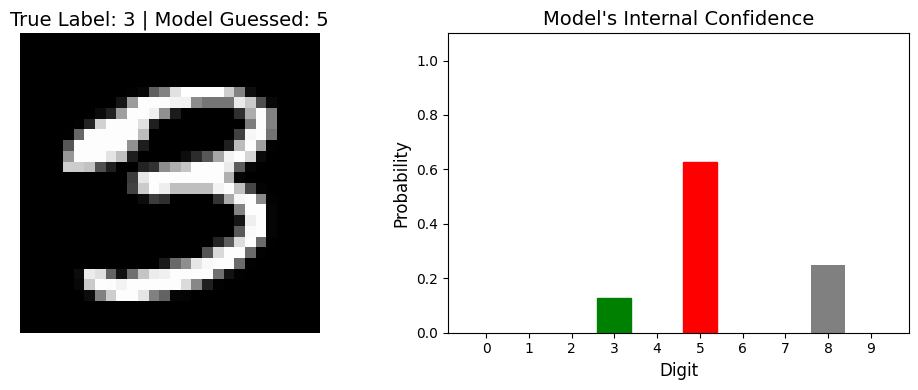

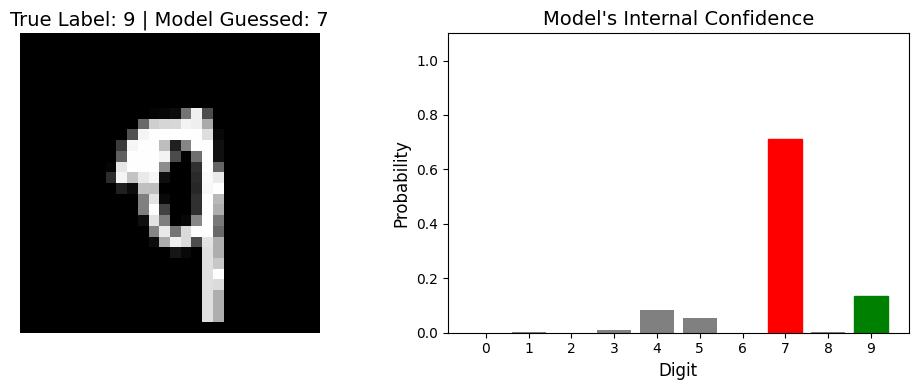

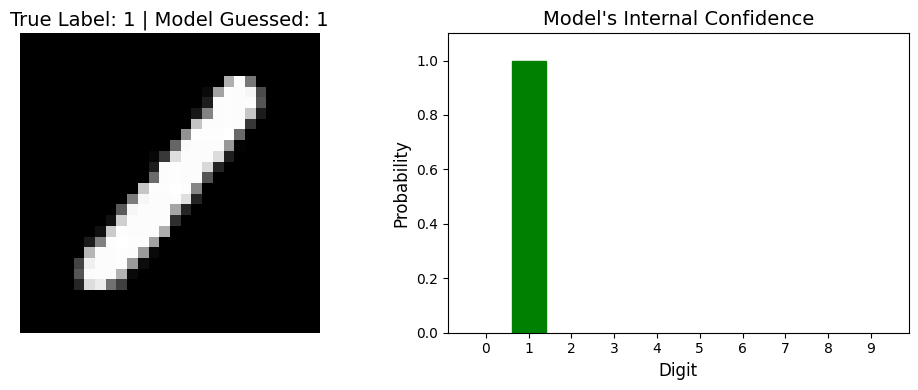

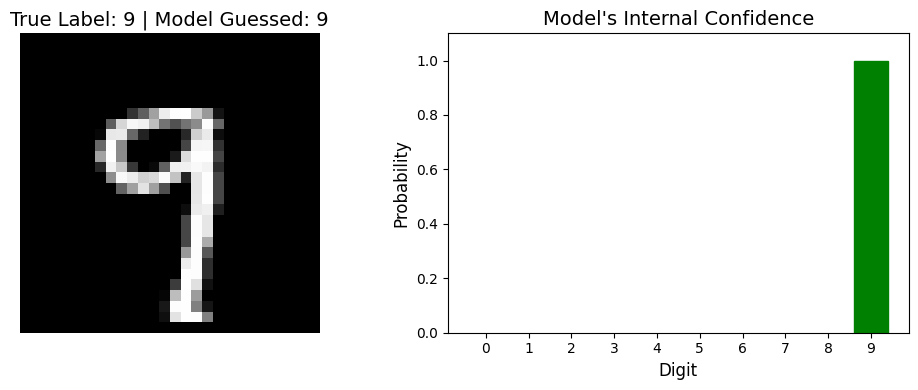

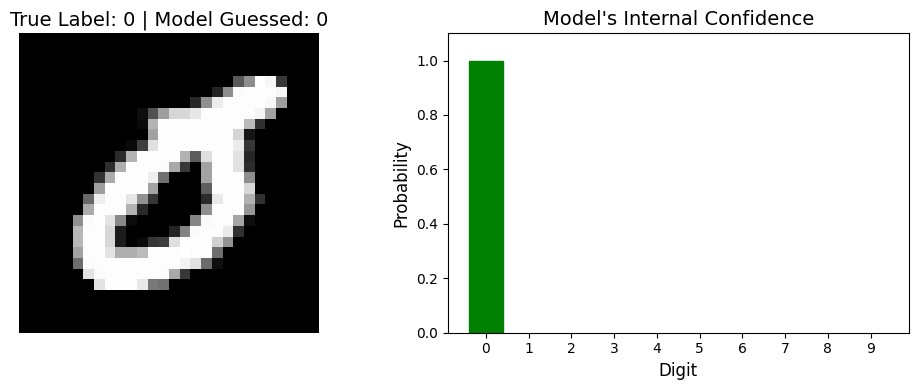

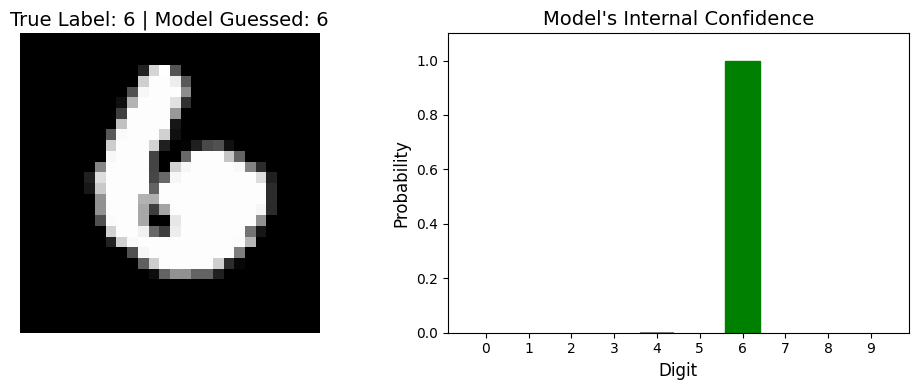

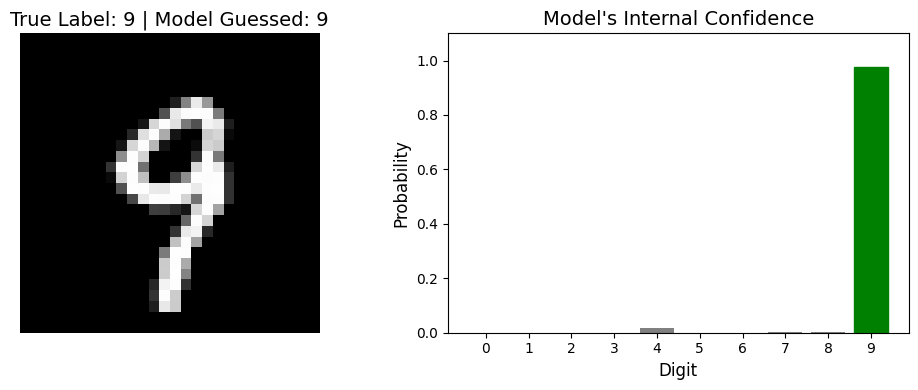

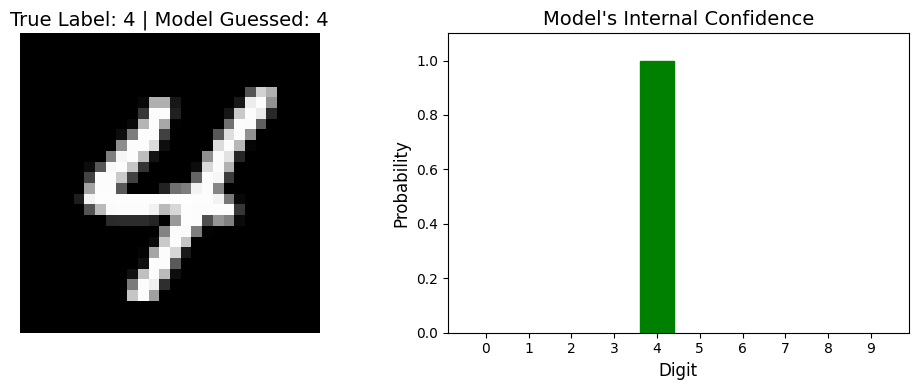

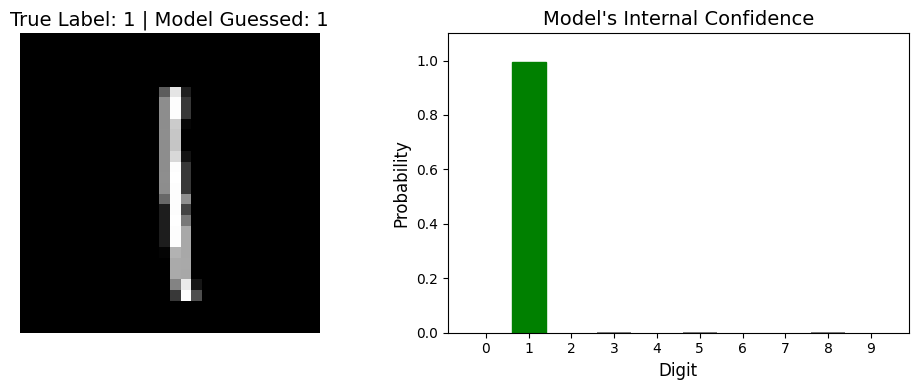

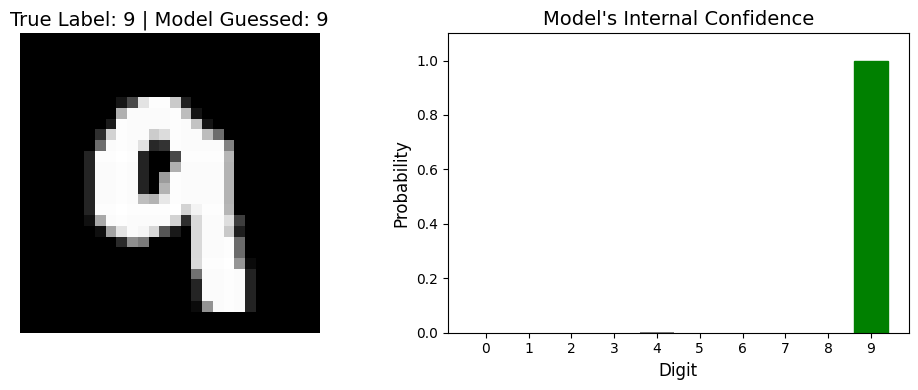

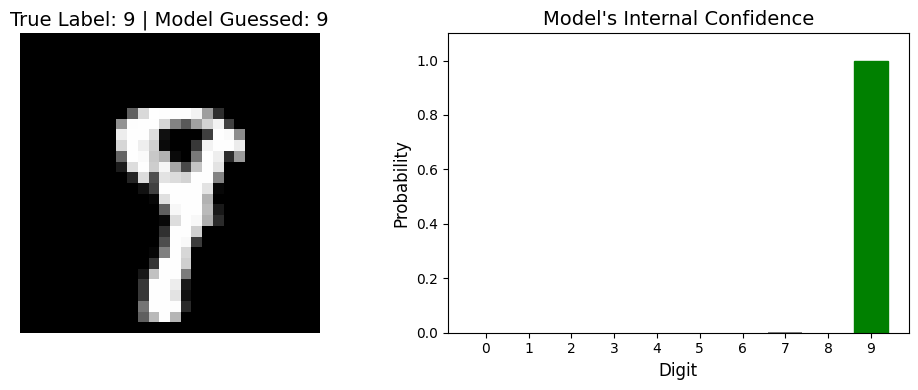

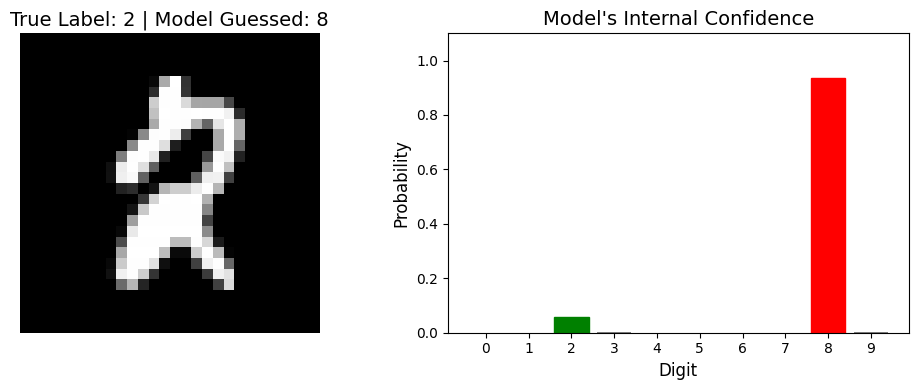

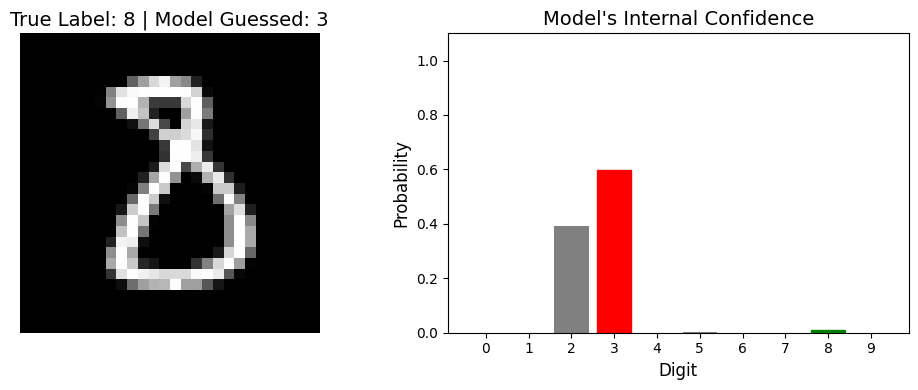

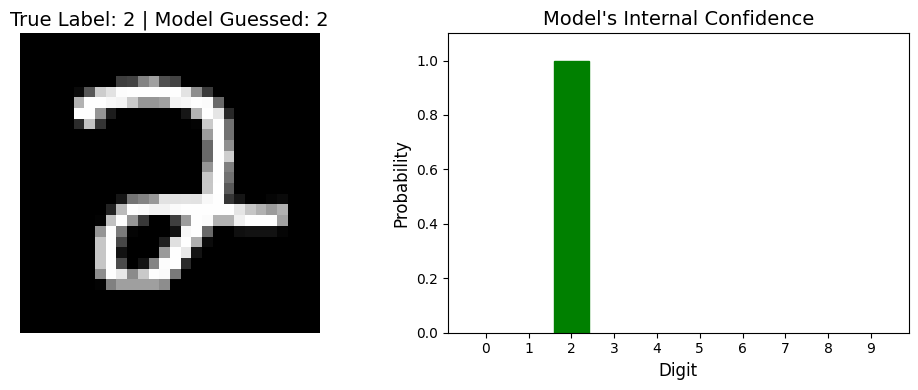

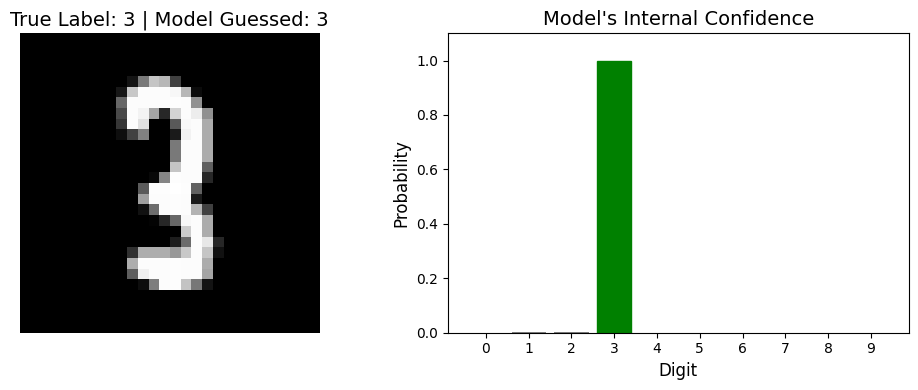

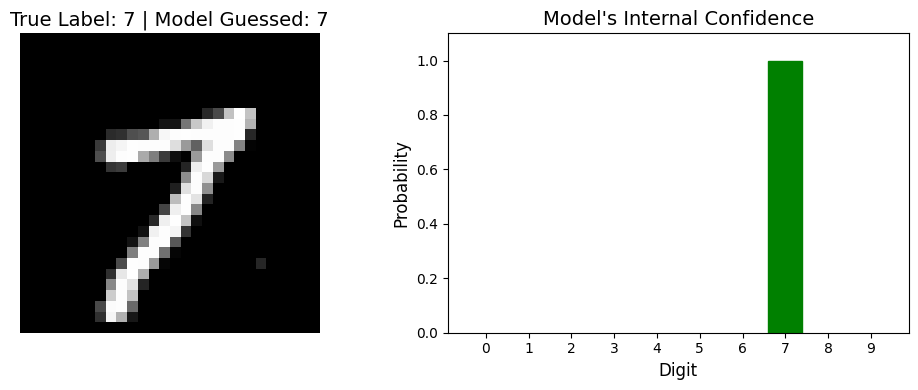

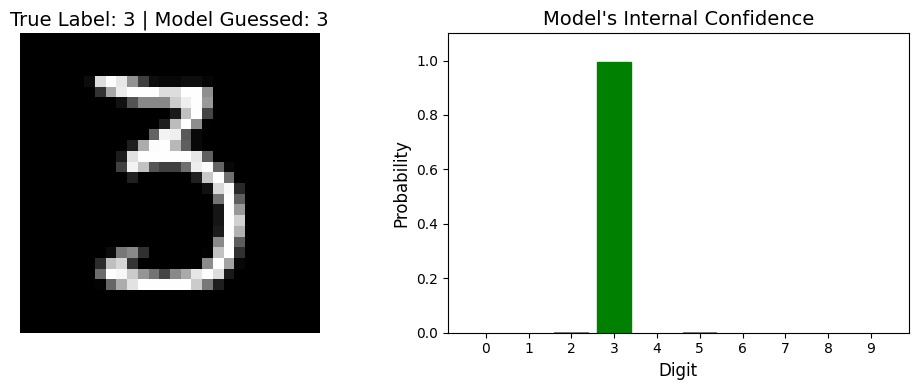

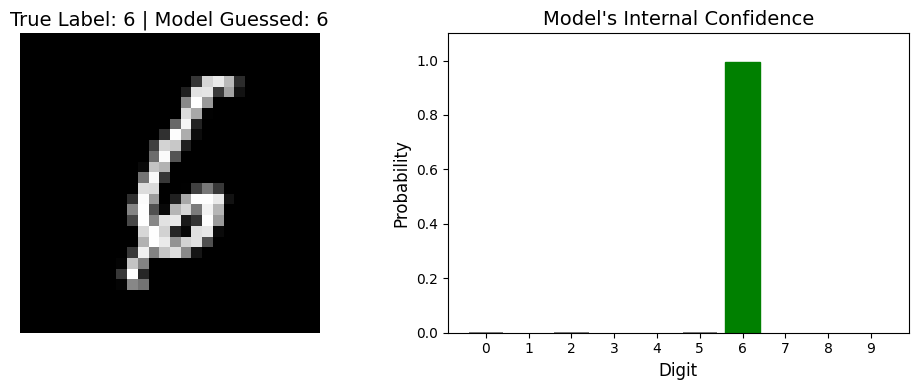

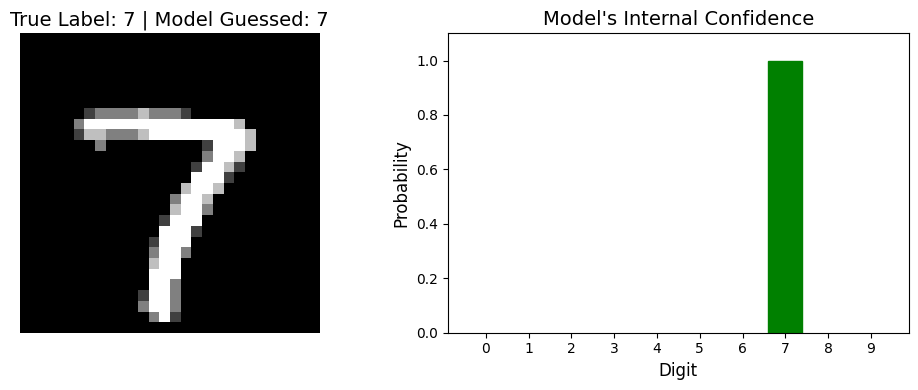

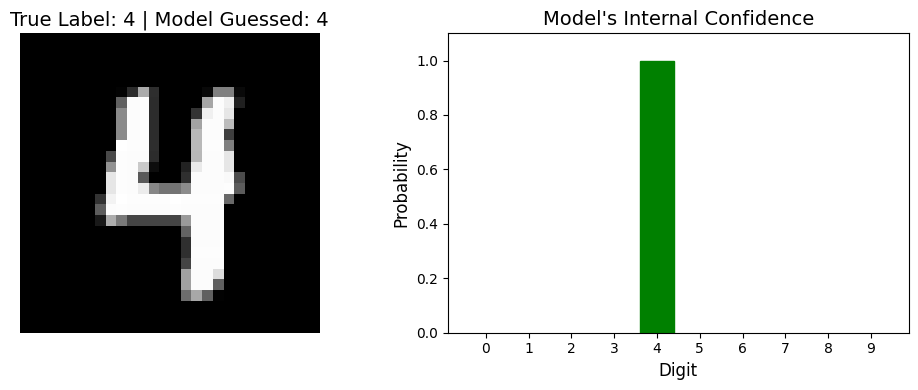

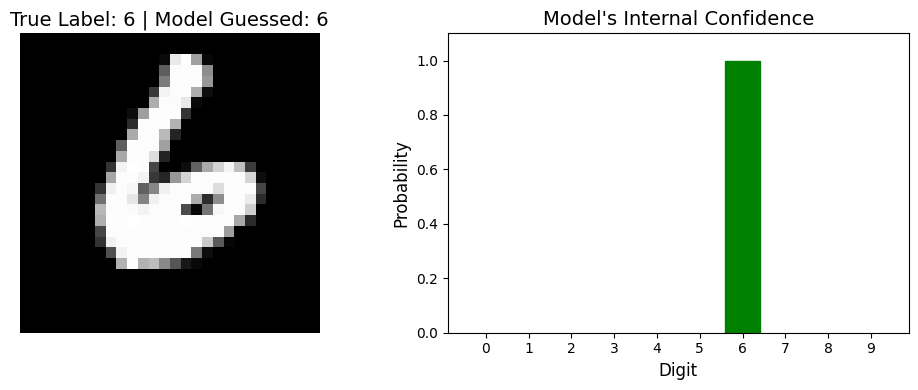

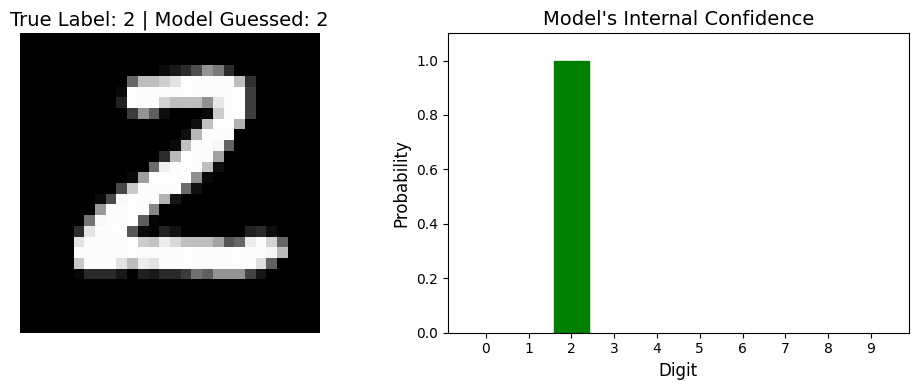

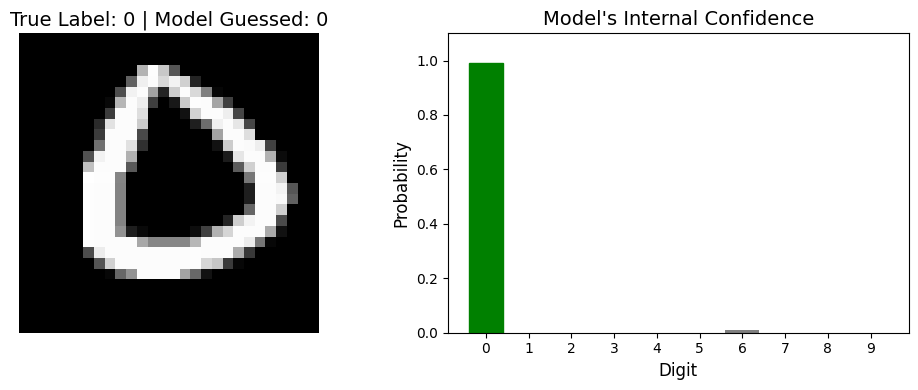

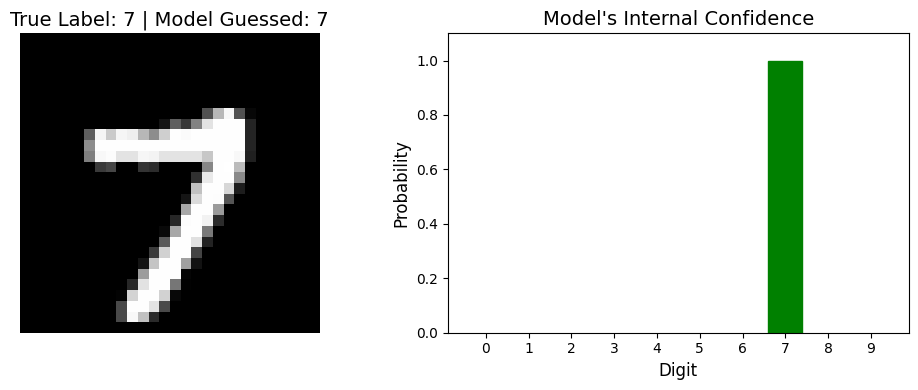

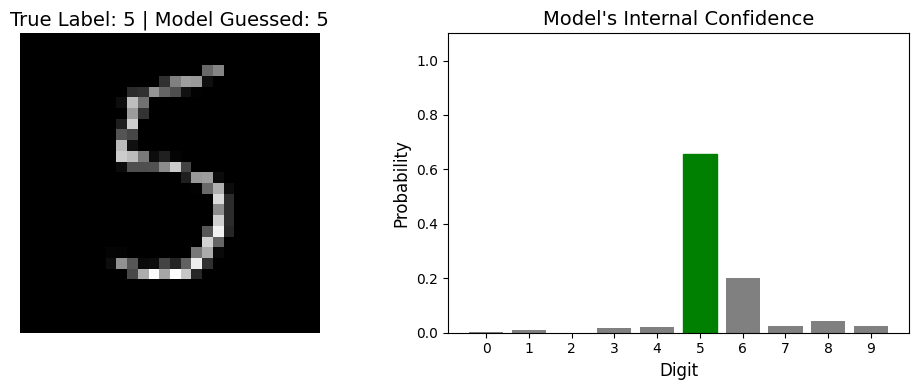

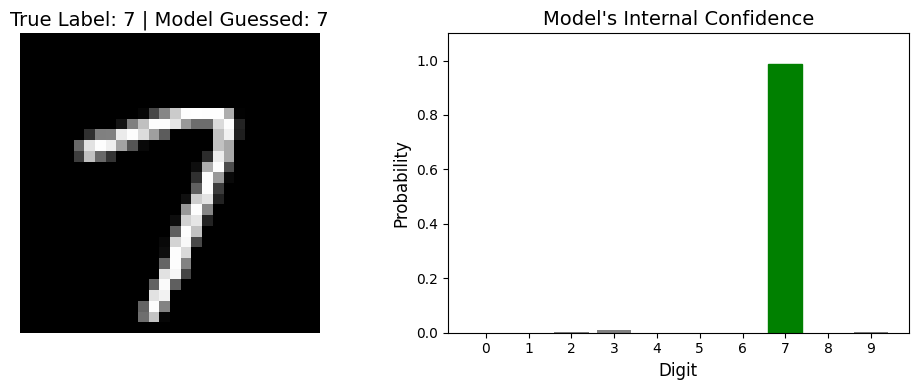

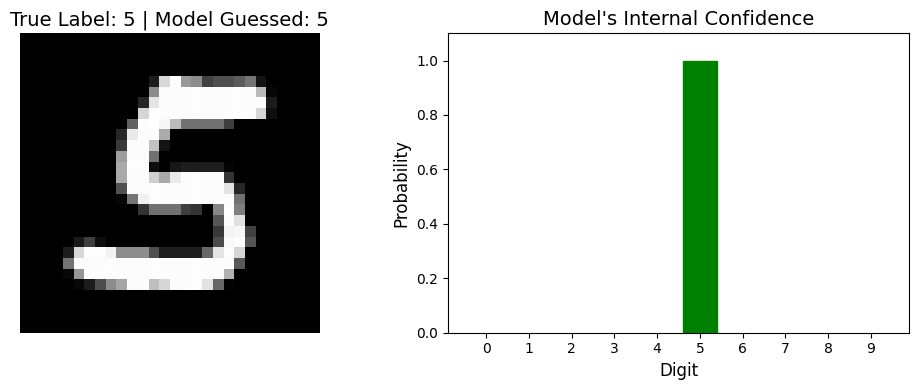

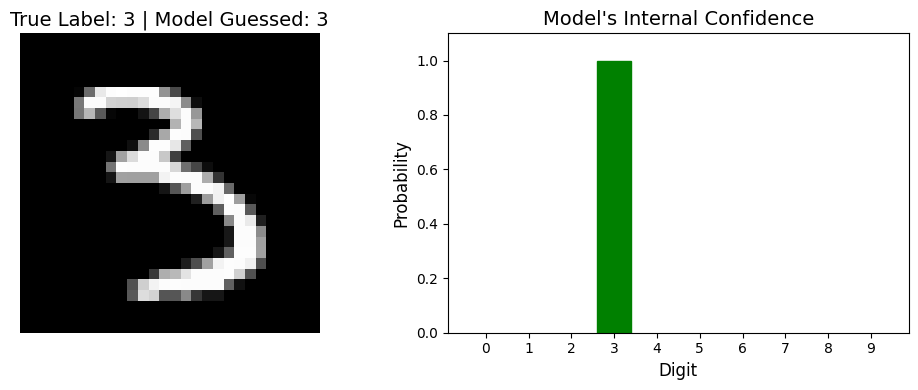

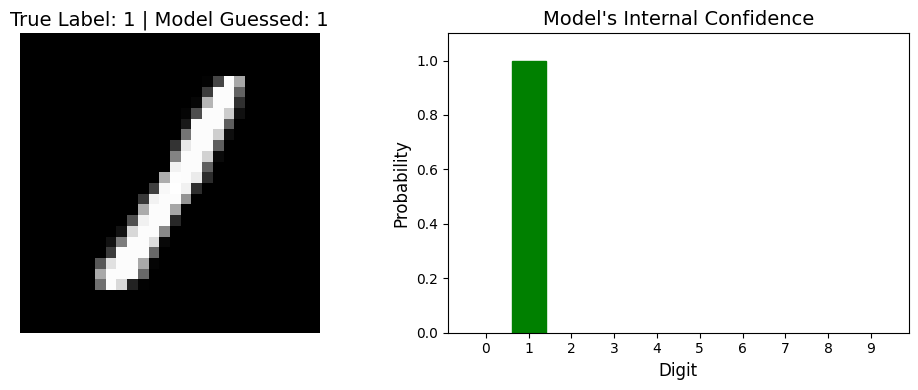

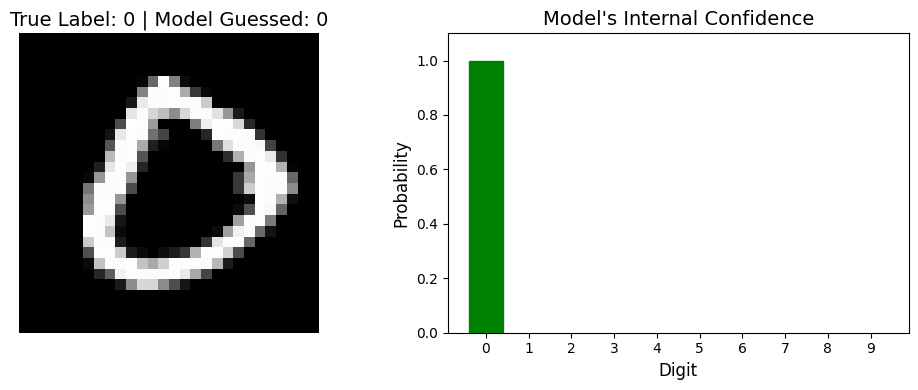

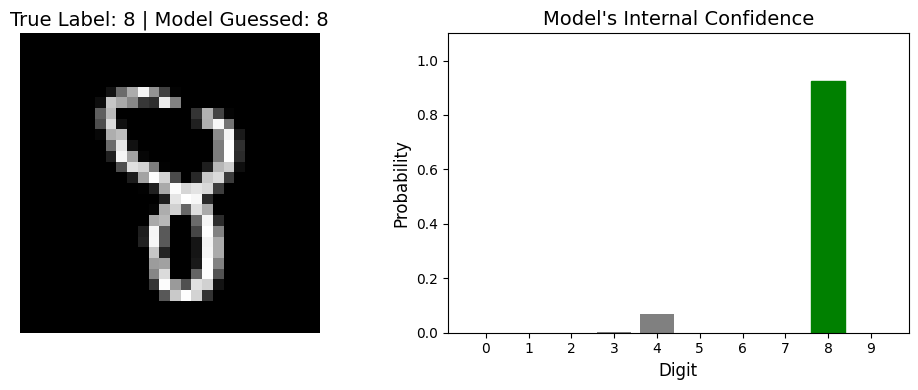

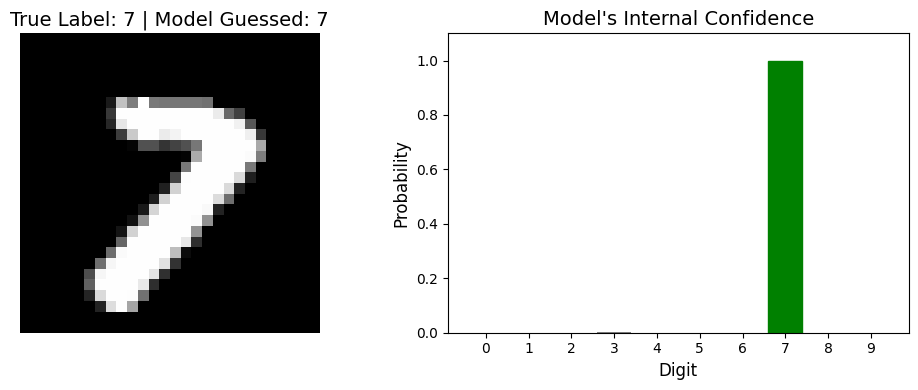

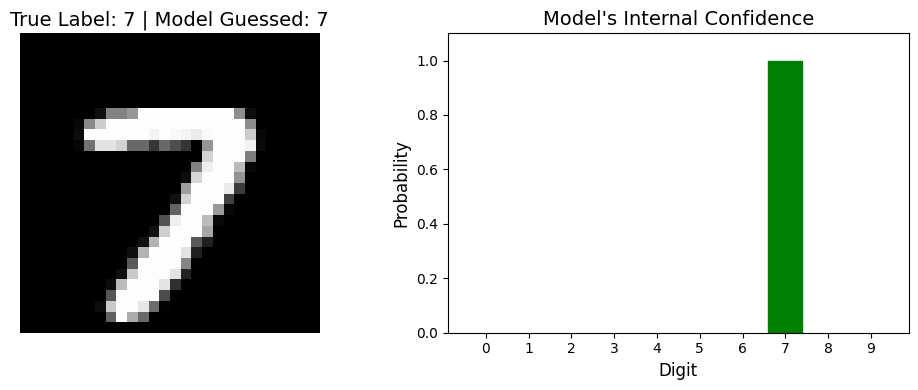

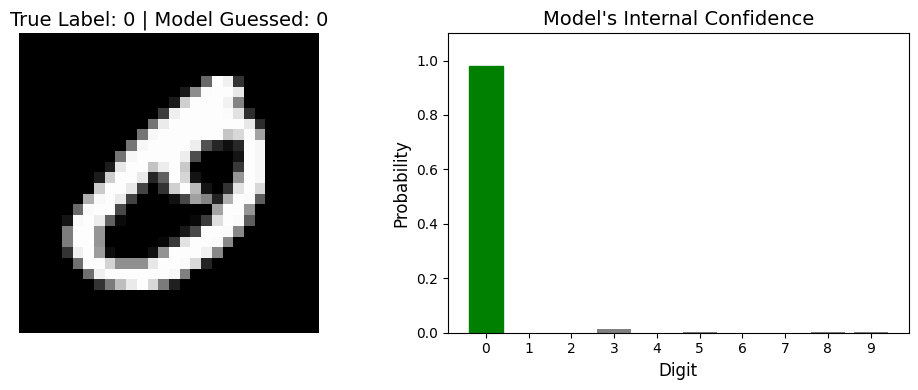

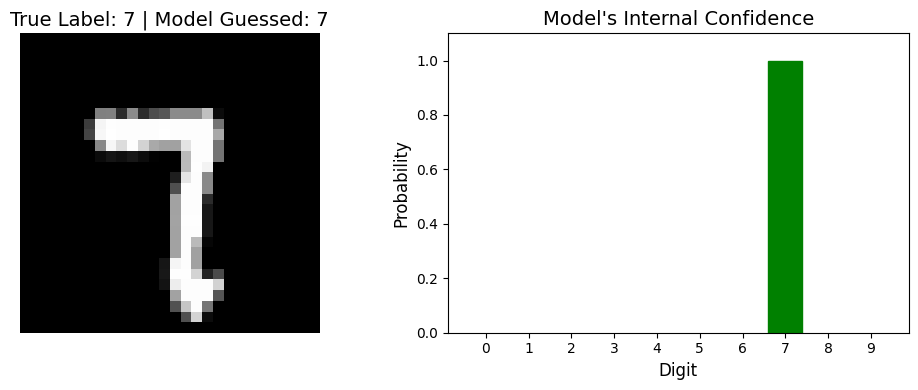

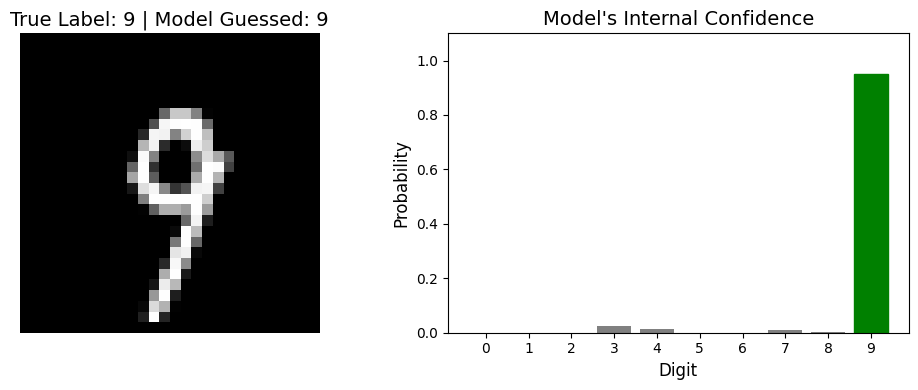

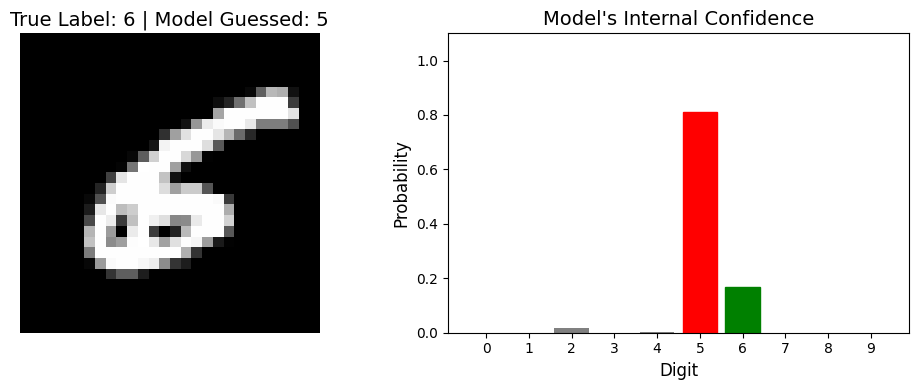

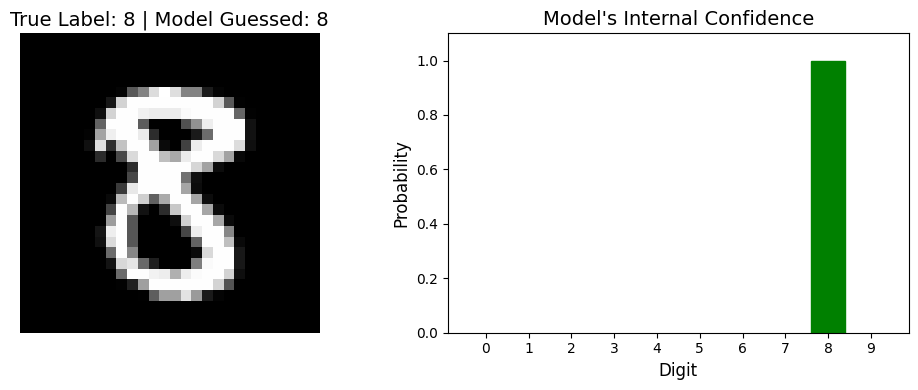

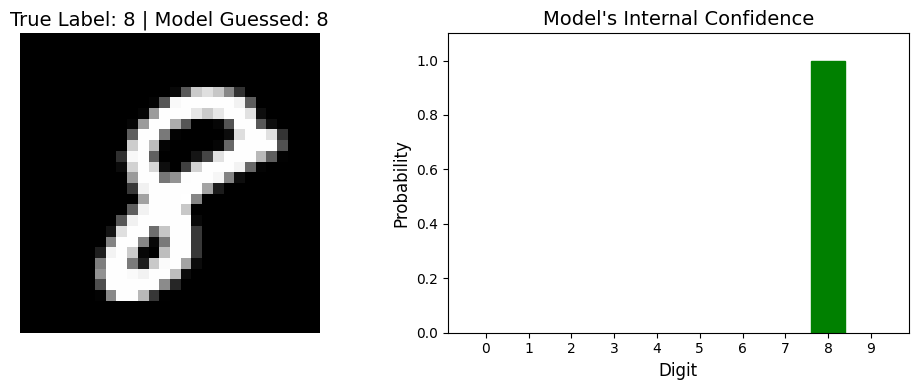

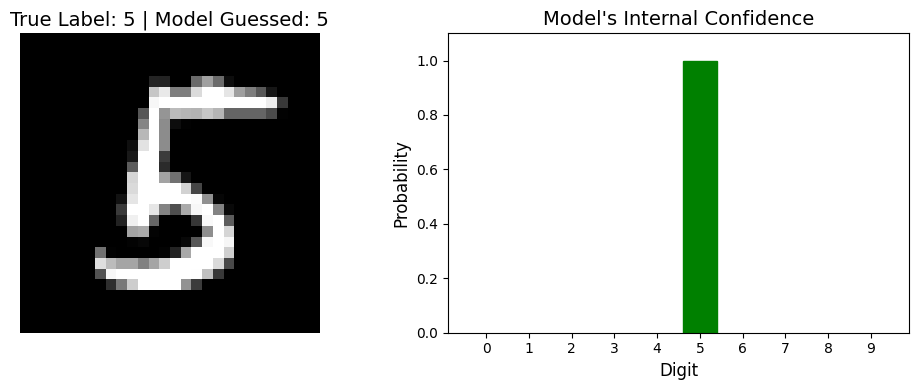

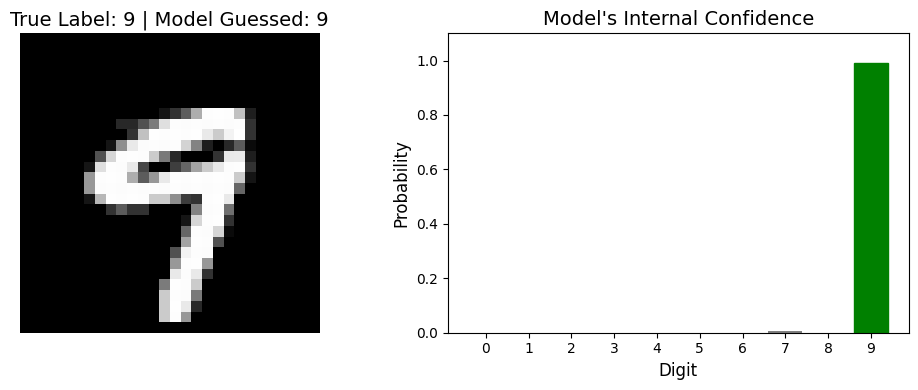

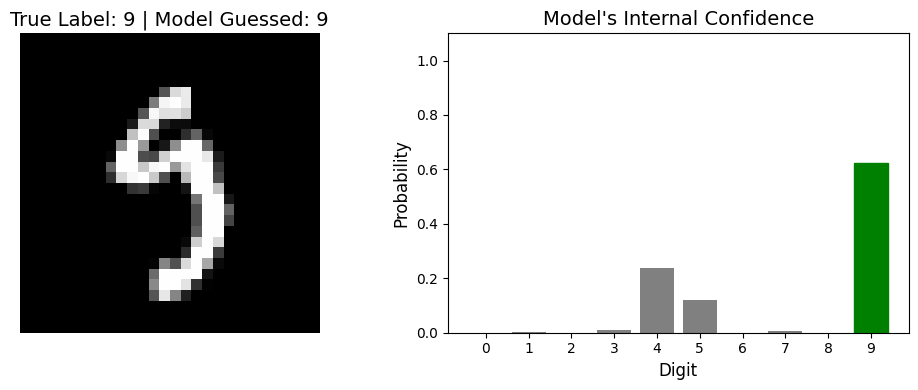

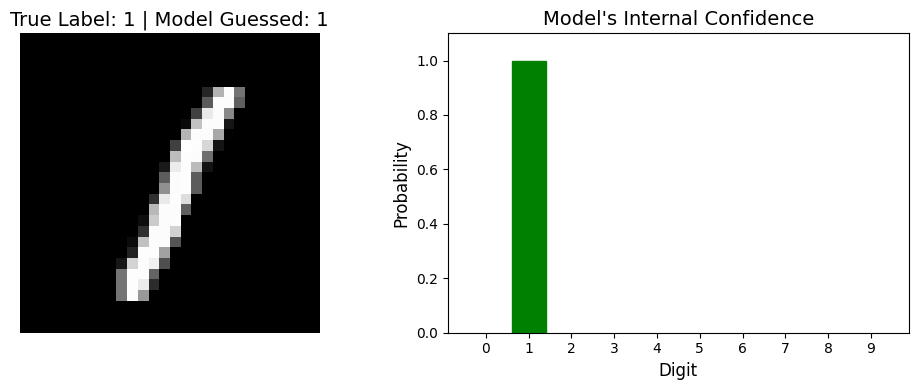

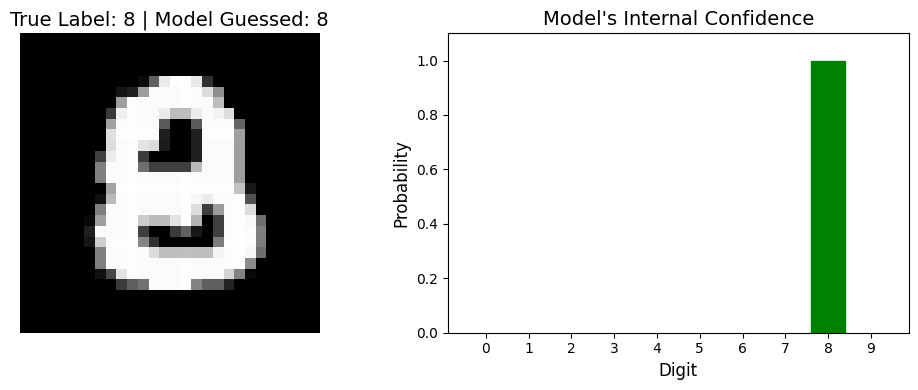

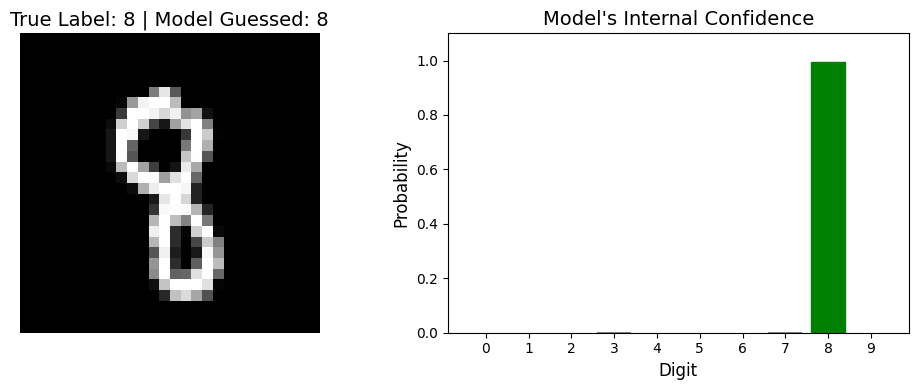

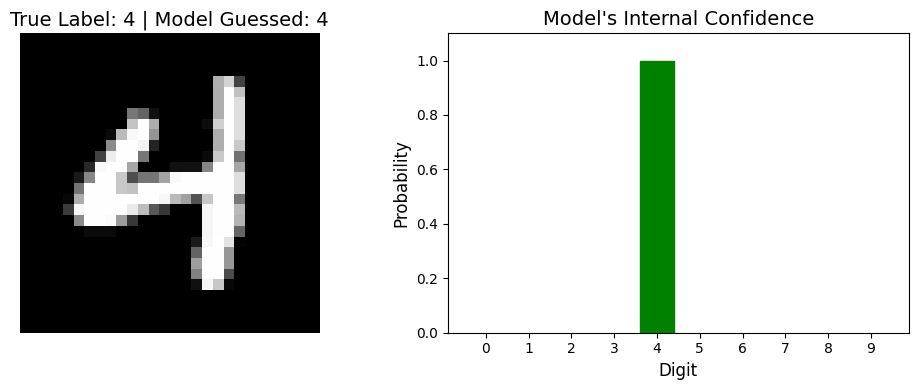

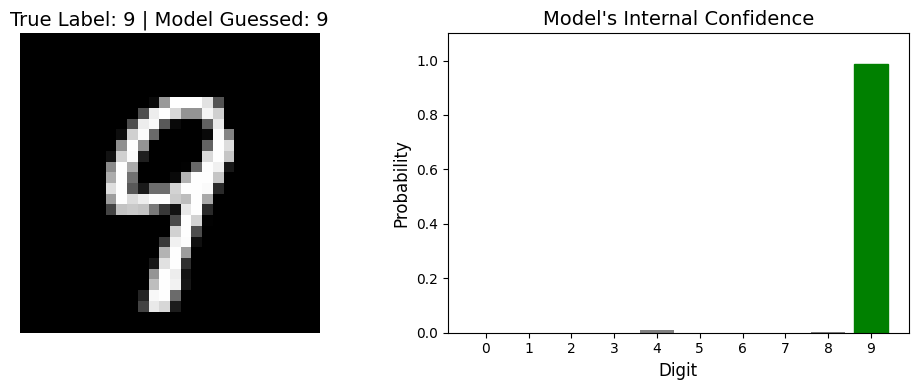

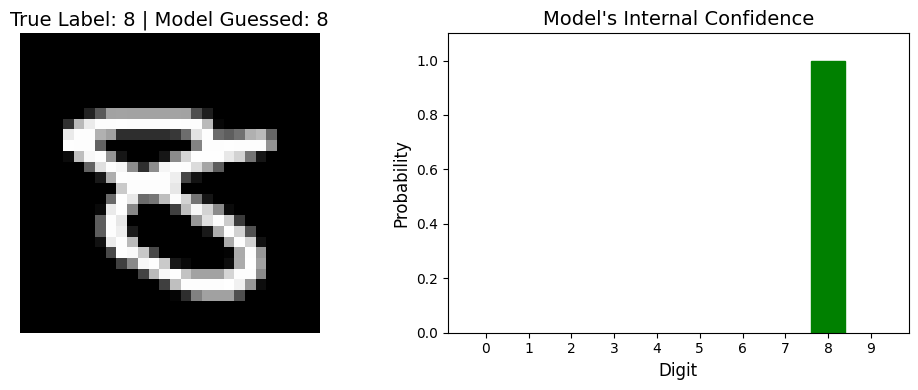

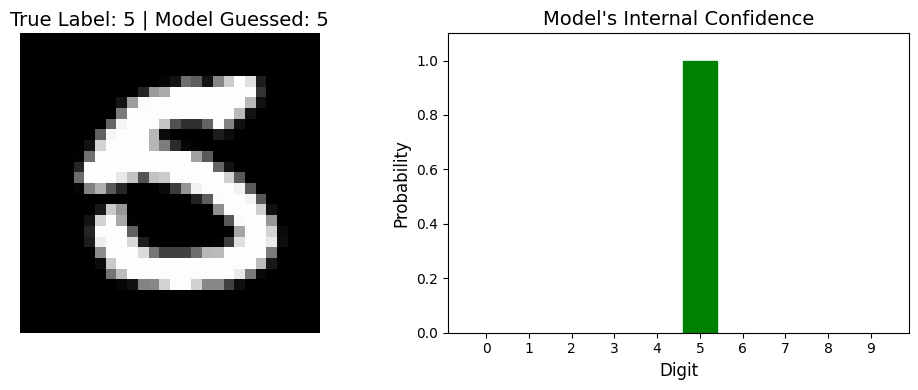

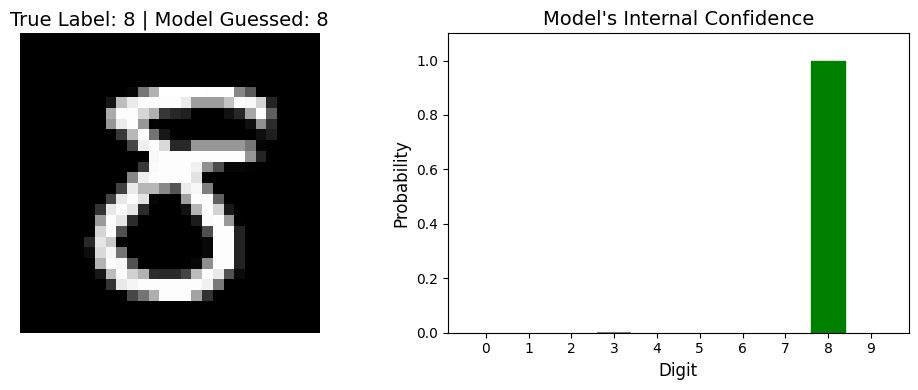

In [ ]:
from matplotlib import pyplot as plt

def visualise_prediction(index):
    image = testPics[:, index].get().reshape(28, 28)
    probabilities = pred[:, index].get()
    
    network_guess = int(predictions[index].get())
    true_answer = int(testLabels[index].get())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
    
    ax1.imshow(image, cmap='gray')
    ax1.set_title(f"True Label: {true_answer} | Model Guessed: {network_guess}", fontsize = 14)
    ax1.axis('off')

    bars = ax2.bar(range(10), probabilities, color = "gray")
    ax2.set_xticks(range(10))
    ax2.set_ylim([0, 1.1])
    ax2.set_xlabel("Digit", fontsize = 12)
    ax2.set_ylabel("Probability", fontsize = 12)
    ax2.set_title("Model's Internal Confidence", fontsize = 14)
    
    bars[network_guess].set_color("red") 
    
    bars[true_answer].set_color("green")
    
    plt.tight_layout()
    plt.show()

for i in range(50): # adjust displayed images range
    visualise_prediction(i)